# 02 · Faster R-CNN (two-stage, anchor-based)

Rubric: *Two-stage Anchor-based*. Same protocol as all models: 3-fold GroupKFold by clip (`splits.json`), train on every 20th frame, validate on every 10th, 640 px, 12 epochs, COCO metrics with ignored regions as `iscrowd=1`.

Code: training/evaluation in `tv_train.py` (shared with RetinaNet), data in `tv_dataset.py`, metrics and logging in `common.py`.

**Result:** anchors ×0.5 give the best Faster R-CNN: OOF mAP 0.116, AP50 0.264, AP_small 0.034, 23 FPS (baseline 0.113 / 0.250 / 0.031). Small objects remain the main weakness: the RPN finds most of them, the second stage loses them.

## 1. Run configuration
`MODE`: `"quick"` (smoke test, minutes) or `"full"` (all folds, GPU). `EXPERIMENT`: a key of `EXPERIMENTS` (section 3). `FOLDS`: folds trained in this session. `RUN_ANALYSIS`: run section 7.

In [1]:
MODE = "full"
EXPERIMENT = "frcnn_anch05"
FOLDS = [0, 1, 2]
RUN_ANALYSIS = True
ANALYSIS_EXPERIMENT = "auto"
PROPOSAL_SWEEP = [300, 1000, 2000]

## 2. Setup
Use the shared modules next to this notebook, or download them from the repo (Kaggle).

In [2]:
import os
import sys
import time
import urllib.request
from pathlib import Path

REPO_RAW = "https://raw.githubusercontent.com/KaplyshOlha/hw-2/main/notebooks/"
SRC_FILES = ["common.py", "tv_dataset.py", "tv_train.py", "splits.json", "anchors.json"]
SRC = next((Path(p) for p in [".", "notebooks"] if all((Path(p) / f).exists() for f in SRC_FILES)), None)
if SRC is None:
    SRC = Path("/tmp/hw2_src")
    SRC.mkdir(parents=True, exist_ok=True)
    for f in SRC_FILES:
        urllib.request.urlretrieve(REPO_RAW + f, SRC / f)
sys.path.insert(0, str(SRC.resolve()))

Imports, output paths and device. FULL mode stops if no GPU is attached.

In [3]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

import common
import tv_train as tvt

assert MODE in ("quick", "full")
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
RUN_ROOT = WORK / ("runs" if MODE == "full" else "runs_quick")
RESULTS = WORK / ("results.csv" if MODE == "full" else "results_quick.csv")
IMG_DIR = WORK / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)
INPUT_ROOT = os.environ.get("HW2_INPUTS", "/kaggle/input")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if MODE == "full":
    assert DEVICE.type == "cuda", "FULL mode needs a GPU (Settings -> Accelerator -> GPU T4)"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight"})
print(f"MODE={MODE} EXPERIMENT={EXPERIMENT} FOLDS={FOLDS} "
      f"device={torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'cpu'} src={SRC}")

MODE=full EXPERIMENT=frcnn_anch05 FOLDS=[0, 1, 2] device=Tesla T4 src=/tmp/hw2_src


Copy finished folds and `results.csv` from previous notebook versions attached as input, so nothing is retrained.

In [4]:
tvt.restore_from_inputs(RUN_ROOT, RESULTS, INPUT_ROOT, name=RUN_ROOT.name);

restored 6 fold dirs from /kaggle/input


## 3. Experiments
Shared training setup (`tvt.Config`): COCO-pretrained `fasterrcnn_resnet50_fpn`, new 9-class head (8 + background), SGD (momentum 0.9, wd 1e-4), batch 8, LR 0.01 (linear scaling of 0.02 for batch 16), 200 warmup iterations, 12 epochs, LR ×0.1 at epochs 8 and 11, AMP, horizontal flip. Ignored regions are painted gray in training frames; validation frames stay raw, like the test set. `score_thresh=0.001`, `detections_per_img=300` (up to 180 objects per frame).

| experiment | change | why |
|---|---|---|
| `frcnn_base` | torchvision defaults (anchors 32–512) | reference |
| `frcnn_anch05` | anchors ×0.5 → 16–256 | median object is 15 px at 640; a 15×15 box has IoU 0.22 with the smallest default anchor (32×32) |
| `frcnn_roi05` | + RoI positive fraction 0.25 → 0.5 | 512 × 0.25 = max 128 positive RoIs, but 7.5% of frames have >100 objects |
| `frcnn_giou` | + GIoU box loss (weight 10, as in mmdetection) | smooth L1 on offsets ignores overlap; GIoU is scale-invariant |

`frcnn_base` and `frcnn_anch05` were trained. `frcnn_roi05` and `frcnn_giou` are implemented (one change each relative to `frcnn_anch05`) but were not run within the GPU budget. The number of RPN proposals is tested at inference only (section 7.1).

In [5]:
BASE = tvt.Config(experiment="frcnn_base", model="faster_rcnn", anchors_json=str(SRC / "anchors.json"),
                  notes="torchvision defaults, COCO-pretrained, 640px")
EXPERIMENTS = {"frcnn_base": BASE}
EXPERIMENTS["frcnn_anch05"] = tvt.make_config(
    BASE, experiment="frcnn_anch05", anchor_key="x0.5", notes="anchors x0.5 (16-256)")
EXPERIMENTS["frcnn_roi05"] = tvt.make_config(
    EXPERIMENTS["frcnn_anch05"], experiment="frcnn_roi05", box_positive_fraction=0.5,
    notes="anch05 + RoI positive fraction 0.5")
EXPERIMENTS["frcnn_giou"] = tvt.make_config(
    EXPERIMENTS["frcnn_anch05"], experiment="frcnn_giou", box_loss="giou", box_loss_weight=10.0,
    notes="anch05 + GIoU box loss (w=10)")
EXPERIMENTS["frcnn_roi05_giou"] = tvt.make_config(
    EXPERIMENTS["frcnn_roi05"], experiment="frcnn_roi05_giou", box_loss="giou", box_loss_weight=10.0,
    notes="anch05 + RoI pos 0.5 + GIoU")

QUICK = dict(epochs=2, max_iters=15, batch_size=2, train_stride=100, eval_stride=200,
             warmup_iters=10, milestones=(1,), fps_warmup=3, fps_iters=10)


def get_cfg(name):
    c = EXPERIMENTS[name]
    return tvt.make_config(c, **QUICK) if MODE == "quick" else c


cfg = get_cfg(EXPERIMENT)
pd.Series({k: v for k, v in cfg.key().items() if v != tvt.Config().key().get(k)}, name="changed vs defaults", dtype=object)

experiment    frcnn_anch05
anchor_key            x0.5
Name: changed vs defaults, dtype: object

## 4. Data and folds
Load all labelled frames and the fixed clip-level split; ~920 train and ~910 validation frames per fold.

In [6]:
common.seed_everything()
images, anns = common.load_gt(cache="/tmp/gt_cache.pkl")
splits = common.load_splits(SRC / "splits.json")
pd.DataFrame([{"fold": f["fold"], "train_clips": len(f["train_clips"]), "val_clips": len(f["val_clips"]),
               "train_frames": len(common.fold_images(images, splits, f["fold"], "train", cfg.train_stride)),
               "val_frames": len(common.fold_images(images, splits, f["fold"], "val", cfg.eval_stride))}
              for f in splits["folds"]]).set_index("fold")

,train_clips,val_clips,train_frames,val_frames
fold,,,,
0,42,21,922,912
1,42,21,923,913
2,42,21,923,909


## 5. Train and predict
Train each fold (finished folds are skipped, interrupted ones resume from `last.pt`), predict the fold's validation frames, measure FPS (batch 1, T4).

In [7]:
t0 = time.time()
if MODE == "quick":
    try:
        tvt.run_experiment(tvt.make_config(cfg, stop_after_epoch=1), images, anns, splits, FOLDS[:1],
                           RUN_ROOT, RESULTS, DEVICE)
    except tvt.Interrupted as e:
        print("resume test:", e)
metrics = tvt.run_experiment(cfg, images, anns, splits, FOLDS, RUN_ROOT, RESULTS, DEVICE,
                             require_all_folds=(MODE == "full"))
print(f"total {(time.time() - t0) / 60:.1f} min")

[frcnn_anch05] fold 0: already done, skipped
[frcnn_anch05] fold 1: already done, skipped
[frcnn_anch05] fold 2: already done, skipped
total 7.9 min


OOF metrics of this experiment: per fold, mean ± std, and pooled out-of-fold (`oof`).

In [8]:
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR500"]
PER_CLASS = [f"AP_{c}" for c in common.CLASSES]
if metrics is not None:
    display(metrics[MAIN].round(4))
    display(metrics.loc[["oof"], PER_CLASS].round(4))

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500
0,0.1155,0.2510,0.0942,0.0418,0.0930,0.2382,0.2642
1,0.1224,0.2792,0.0912,0.0388,0.1137,0.2518,0.2645
2,0.1245,0.2901,0.0942,0.0375,0.1133,0.2368,0.3003
mean,0.1208,0.2735,0.0932,0.0394,0.1067,0.2423,0.2764
std,0.0039,0.0165,0.0014,0.0018,0.0097,0.0068,0.0169
oof,0.1158,0.2637,0.0880,0.0344,0.1023,0.2368,0.2744


,AP_person,AP_bicycle,AP_car,AP_van,AP_truck,AP_tricycle,AP_bus,AP_motor
oof,0.1326,0.0171,0.3323,0.0933,0.0332,0.0952,0.1502,0.0759


## 6. Comparison of experiments
Latest logged run of each experiment from `results.csv`.

In [9]:
names = [n for n in EXPERIMENTS if (RUN_ROOT / n).exists()]
summ = tvt.summary(RESULTS, model="faster_rcnn", experiments=names)
if len(summ):
    table = pd.DataFrame({m: summ[f"{m}_oof"].round(4) for m in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AR500"]})
    table["mAP mean±std"] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(summ["mAP_mean"], summ["mAP_std"])]
    table["FPS"] = summ["fps"].round(1)
    table["train min/fold"] = summ["train_min"].round(1)
    table.to_csv(WORK / "02_frcnn_comparison.csv")
    display(table)

,mAP,AP50,AP75,AP_small,AP_medium,AR500,mAP mean±std,FPS,train min/fold
experiment,,,,,,,,,
frcnn_base,0.1131,0.2501,0.090,0.0307,0.0929,0.2603,0.1188 ± 0.0036,24.6,9.2
frcnn_anch05,0.1158,0.2637,0.088,0.0344,0.1023,0.2744,0.1208 ± 0.0039,23.2,9.8


Metrics with fold std as error bars, and per-class OOF AP.

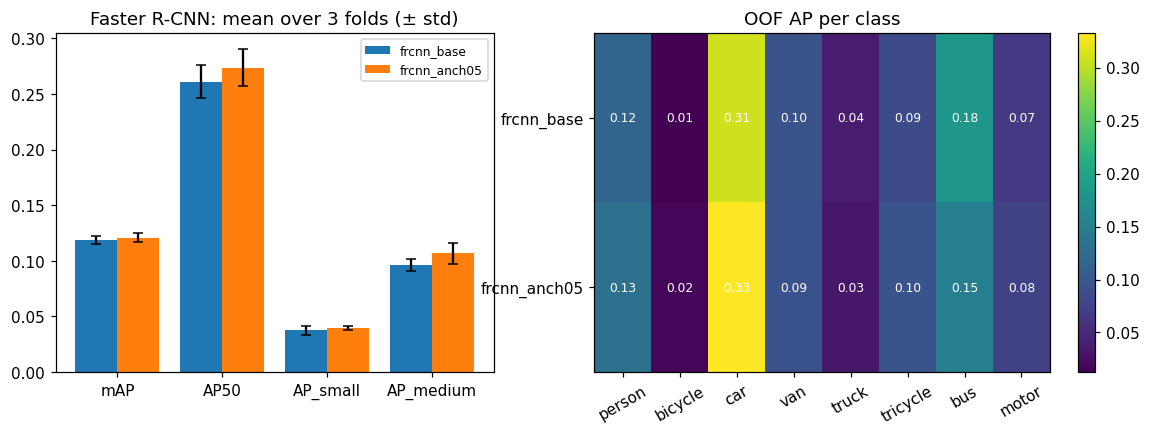

In [10]:
if len(summ):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.3]})
    ms = ["mAP", "AP50", "AP_small", "AP_medium"]
    x = np.arange(len(ms))
    w = 0.8 / len(summ)
    for i, (n, r) in enumerate(summ.iterrows()):
        ax[0].bar(x + i * w, [r[f"{m}_mean"] for m in ms], w, yerr=[r[f"{m}_std"] for m in ms],
                  capsize=3, label=n)
    ax[0].set_xticks(x + w * (len(summ) - 1) / 2, ms)
    ax[0].set_title("Faster R-CNN: mean over 3 folds (± std)")
    ax[0].legend(fontsize=8)
    pc = summ[[c for c in PER_CLASS if c in summ]].astype(float)
    im = ax[1].imshow(pc.values, cmap="viridis", aspect="auto")
    ax[1].set_xticks(range(pc.shape[1]), [c[3:] for c in pc.columns], rotation=30)
    ax[1].set_yticks(range(len(pc)), pc.index)
    for (i, j), v in np.ndenumerate(pc.values):
        ax[1].text(j, i, f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
    ax[1].set_title("OOF AP per class")
    fig.colorbar(im, ax=ax[1])
    fig.savefig(IMG_DIR / "02_frcnn_comparison.png")
    plt.show()

Training losses per epoch (fold 0).

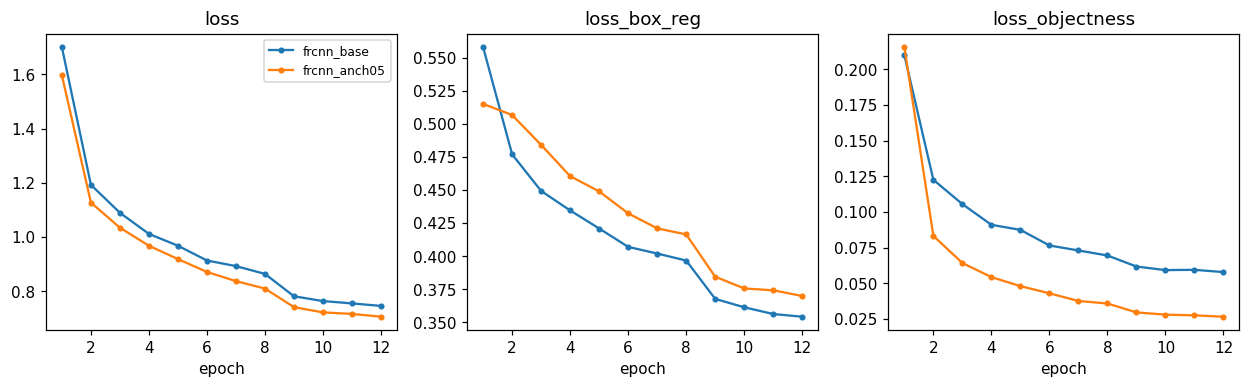

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for n in names:
    done = tvt.load_done(RUN_ROOT, n)
    if 0 not in done:
        continue
    h = pd.DataFrame(done[0]["history"])
    for a, col in zip(ax, ["loss", "loss_box_reg", "loss_objectness"]):
        if col in h:
            a.plot(h["epoch"], h[col], marker="o", ms=3, label=n)
            a.set_title(col)
            a.set_xlabel("epoch")
ax[0].legend(fontsize=8)
fig.savefig(IMG_DIR / "02_frcnn_loss_curves.png")
plt.show()

**Observations**
- **Anchors ×0.5 help, but modestly:** OOF mAP 0.113 → 0.116, AP_small 0.031 → 0.034 (+12%), AP50 0.250 → 0.264, AR500 0.260 → 0.274. The mAP gain is smaller than the fold std (0.004), so it is a small but consistent improvement on all three folds.
- **Large objects lost a little:** bus AP 0.18 → 0.15, AP_large 0.245 → 0.237, because the largest anchor dropped from 512 to 256 px.
- **Localisation is weak:** AP50 is 3× AP75 for both models; a 1–2 px shift is a large IoU error on a 15 px object.
- **Training converged:** losses drop sharply at epoch 9 (LR decay) and flatten; both models take ~9–10 min per fold, ~23–25 FPS.
- **Folds agree** (mAP std ≈ 0.004), so the clip-level split gives a stable estimate.

## 7. Analysis
Analysed experiment: the best by OOF mAP, `frcnn_anch05`. Uses the saved `final.pt` weights of each fold.

In [12]:
DO_ANALYSIS = RUN_ANALYSIS or MODE == "quick"
if ANALYSIS_EXPERIMENT == "auto":
    ANALYSIS_EXPERIMENT = summ["mAP_oof"].idxmax() if len(summ) else EXPERIMENT
acfg = get_cfg(ANALYSIS_EXPERIMENT)
adone = sorted(tvt.load_done(RUN_ROOT, ANALYSIS_EXPERIMENT))
apreds = tvt.load_fold_preds(RUN_ROOT, ANALYSIS_EXPERIMENT)
DO_ANALYSIS = DO_ANALYSIS and len(adone) > 0
print(f"analysis of {ANALYSIS_EXPERIMENT}, folds {adone}, enabled={DO_ANALYSIS}")

analysis of frcnn_anch05, folds [0, 1, 2], enabled=True


### 7.1 Number of RPN proposals at test time
Same weights, 300 / 1000 / 2000 proposals per image; no retraining.

In [13]:
sweep = {}
if DO_ANALYSIS:
    for n in PROPOSAL_SWEEP:
        if n == acfg.rpn_post_nms_top_n_test:
            p, fps = apreds, {k: d["fps"] for k, d in tvt.load_done(RUN_ROOT, ANALYSIS_EXPERIMENT).items()}
        else:
            p, fps = tvt.predict_from_checkpoints(acfg, images, anns, splits, RUN_ROOT, DEVICE,
                                                  rpn_topn=(max(1000, n), n))
        m = common.evaluate_oof(p, images, anns, splits, eval_stride=acfg.eval_stride)
        sweep[n] = {**m.loc["oof", ["mAP", "AP50", "AP_small", "AR500"]].to_dict(),
                    "mAP_std": m.loc["std", "mAP"], "fps": float(np.nanmean(list(fps.values())))}
        logged = set(pd.read_csv(RESULTS)["experiment"]) if RESULTS.exists() else set()
        name = f"{ANALYSIS_EXPERIMENT}_prop{n}"
        if (n != acfg.rpn_post_nms_top_n_test and MODE == "full" and len(p) == splits["n_folds"]
                and name not in logged):
            common.log_results(m, path=RESULTS, owner=acfg.owner, model=acfg.model,
                               experiment=name, train_stride=acfg.train_stride,
                               eval_stride=acfg.eval_stride, imgsz=acfg.imgsz, epochs=acfg.epochs,
                               fps=round(sweep[n]["fps"], 1), notes=f"inference-only: {n} RPN proposals")
    sweep = pd.DataFrame(sweep).T.rename_axis("proposals")
    display(sweep.round(4))

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
[frcnn_anch05] fold 0: re-predicted 912 frames in 37s, rpn_topn=(1000, 300)
[frcnn_anch05] fold 1: re-predicted 913 frames in 27s, rpn_topn=(1000, 300)
[frcnn_anch05] fold 2: re-predicted 909 frames in 30s, rpn_topn=(1000, 300)
[frcnn_anch05] fold 0: re-predicted 912 frames in 47s, rpn_topn=(2000, 2000)
[frcnn_anch05] fold 1: re-predicted 913 frames in 48s, rpn_topn=(2000, 2000)
[frcnn_anch05] fold 2: re-predicted 909 frames in 47s, rpn_topn=(2000, 2000)


,mAP,AP50,AP_small,AR500,mAP_std,fps
proposals,,,,,,
300,0.1113,0.2530,0.0332,0.2671,0.0048,31.6953
1000,0.1158,0.2637,0.0344,0.2744,0.0039,23.1761
2000,0.1150,0.2623,0.0341,0.2678,0.0033,19.1269


OOF metrics and speed vs number of proposals.

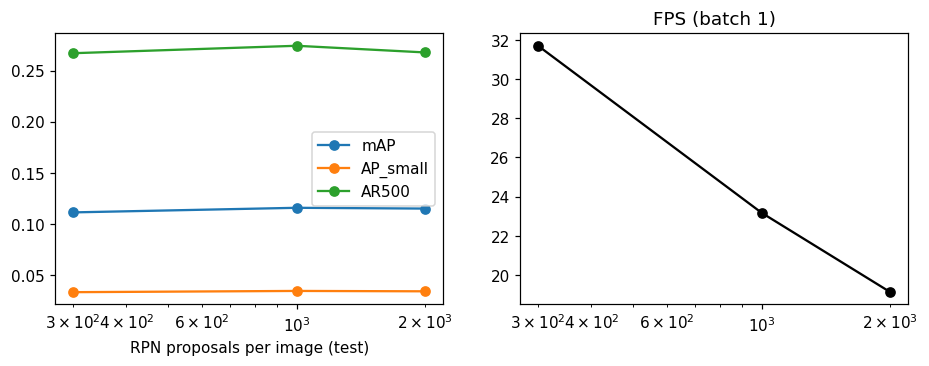

In [14]:
if len(sweep):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    for col in ["mAP", "AP_small", "AR500"]:
        ax[0].plot(sweep.index, sweep[col], marker="o", label=col)
    ax[0].set_xscale("log")
    ax[0].set_xlabel("RPN proposals per image (test)")
    ax[0].legend()
    ax[1].plot(sweep.index, sweep["fps"], marker="o", color="k")
    ax[1].set_xscale("log")
    ax[1].set_title("FPS (batch 1)")
    fig.savefig(IMG_DIR / "02_frcnn_proposal_sweep.png")
    plt.show()

**Observations**
| proposals | OOF mAP | AR500 | FPS |
|---|---|---|---|
| 300 | 0.111 | 0.267 | 31.7 |
| 1000 (trained default) | **0.116** | **0.274** | 23.2 |
| 2000 | 0.115 | 0.268 | 19.1 |

- 1000 is the best setting. 300 loses 0.0045 mAP but is 37% faster; 2000 is 18% slower and no better.
- More proposals cover more objects (section 7.2), but the extra candidates are low-quality and do not become correct detections, so the bottleneck is not the proposal count.

### 7.2 What the RPN and the second stage contribute
**RPN (stage 1)** scores every anchor as object/background and refines it; after NMS it keeps the top-N class-agnostic proposals. It sets the recall ceiling: an object no proposal covers is lost. It also removes the background imbalance: stage 2 sees ~1000 candidates instead of ~10⁵ anchors.

**RoI head (stage 2)** pools a 7×7 feature per proposal (RoIAlign, from the FPN level matching its size), classifies it into 8 classes + background and refines the box per class. It sets precision: rejects background, picks the class, tightens the box.

The table compares proposal recall (top-N, IoU ≥ 0.5, any class) with final detection recall (score ≥ 0.05) by object size (sizes at network scale, 640 px; 300 frames of fold 0).

In [15]:
if DO_ANALYSIS:
    amodel = tvt.load_model(acfg, adone[0], RUN_ROOT, DEVICE)
    _, ava = tvt.make_datasets(acfg, images, anns, splits, adone[0], precache=False)
    pr = tvt.proposal_recall(amodel, ava, DEVICE, topn=(100, 300, 1000, 2000), max_images=300)
    cols = [c for c in pr if c.startswith("prop@")] + ["det_any_class", "det_correct_class"]
    rpn_tab = pr.groupby("size_bin", observed=True)[cols + ["prop_best_iou", "det_best_iou"]].mean()
    rpn_tab.insert(0, "n_gt", pr.groupby("size_bin", observed=True).size())
    rpn_tab.loc["all"] = [len(pr)] + pr[cols + ["prop_best_iou", "det_best_iou"]].mean().tolist()
    display(rpn_tab.round(3))
    del amodel

,n_gt,prop@100,prop@300,prop@1000,prop@2000,det_any_class,det_correct_class,prop_best_iou,det_best_iou
size_bin,,,,,,,,,
<8,1460.0,0.211,0.343,0.466,0.506,0.332,0.278,0.440,0.280
8-16,7830.0,0.469,0.633,0.769,0.813,0.598,0.509,0.589,0.412
16-32,4899.0,0.629,0.783,0.895,0.942,0.811,0.726,0.697,0.569
32-64,1436.0,0.850,0.923,0.964,0.984,0.943,0.897,0.782,0.743
64-128,140.0,0.900,0.964,0.986,1.000,0.993,0.929,0.833,0.810
>128,2.0,1.000,1.000,1.000,1.000,1.000,1.000,0.810,0.901
all,15767.0,0.533,0.682,0.800,0.842,0.675,0.594,0.629,0.482


Recall by object size: proposals vs final detections.

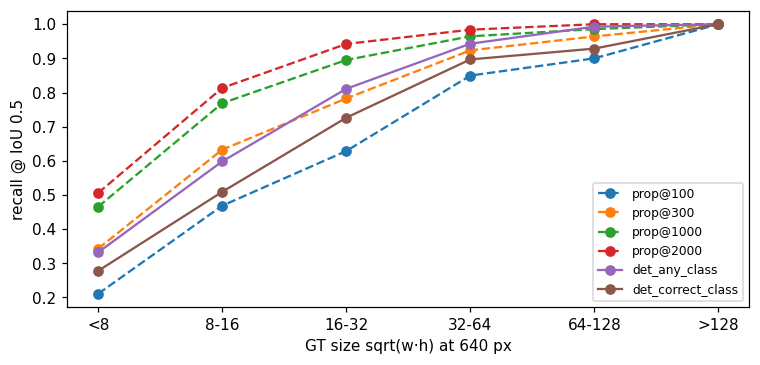

In [16]:
if DO_ANALYSIS:
    t = rpn_tab.drop(index="all")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for c in cols:
        ax.plot(t.index.astype(str), t[c], marker="o", ls="--" if c.startswith("prop") else "-", label=c)
    ax.set_xlabel("GT size sqrt(w·h) at 640 px")
    ax.set_ylabel("recall @ IoU 0.5")
    ax.legend(fontsize=8)
    fig.savefig(IMG_DIR / "02_frcnn_rpn_vs_head.png")
    plt.show()

**Observations**
- **The RPN covers most objects:** top-1000 proposals reach 80% recall overall and 77% for 8–16 px objects; only objects < 8 px are poorly covered (47%).
- **The second stage is where small objects are lost:** final recall with the correct class is 59% overall vs 80% proposal recall; for 8–16 px it is 51% vs 77%, for 32–64 px 90% vs 96%. A 7×7 RoIAlign feature of a 10 px object is mostly upsampled noise, so classification fails even when a proposal is in the right place.
- **Classification adds errors:** any-class recall is 68% vs 59% correct-class, i.e. ~9% of objects are found but labelled with the wrong class.
- Box quality improves in stage 2 for large objects (best IoU 0.81 → 0.90 for >128 px). For small objects the mean "best IoU" of detections is lower than of proposals because missed objects count as 0, so these two columns are not directly comparable there.

### 7.3 Error analysis
Detections with score ≥ 0.3 matched to GT (IoU ≥ 0.5, same class). False positives: `cls` wrong class, `loc` same class with 0.1 ≤ IoU < 0.5, `dup` duplicate, `bkg` background. Sizes in original pixels.

In [17]:
if DO_ANALYSIS:
    oof_ids = np.concatenate([common.fold_images(images, splits, k, "val", acfg.eval_stride)["img_id"].to_numpy()
                              for k in sorted(apreds)])
    gt, dt = tvt.error_analysis(pd.concat(apreds.values(), ignore_index=True), images, anns, oof_ids,
                                score_thr=0.3)
    gt["density"] = pd.cut(gt["n_in_frame"], [0, 20, 50, 100, 1000], labels=["≤20", "21-50", "51-100", ">100"])
    summary_err = pd.Series({"GT objects": len(gt), "recall": gt["matched"].mean(),
                             **dt["type"].value_counts(normalize=True).rename(lambda s: f"dets {s}").to_dict()})
    display(summary_err.round(3).to_frame("value").T)

,GT objects,recall,dets tp,dets bkg,dets loc,dets cls,dets dup
value,123834.0,0.501,0.519,0.183,0.151,0.124,0.023


Recall by size, occlusion and density; which class missed objects were predicted as.

**Observations** (`frcnn_anch05`, score ≥ 0.3): recall 0.50; of all detections 52% are correct, 18% background, 15% poorly localised, 12% wrong class, 2% duplicates.
- **Size is the main factor:** recall 0.13 for 8–16 px, 0.29 for 16–32 px, 0.80 for >128 px.
- **Occlusion:** recall 0.58 (none) → 0.44 (partial) → 0.19 (heavy).
- **Density barely matters:** recall ≈ 0.47–0.53 for any number of objects per frame.
- **Confusions follow visual similarity:** van → car (2243), motor → person (862), bicycle → motor (773), truck → car (602), tricycle → car (473).

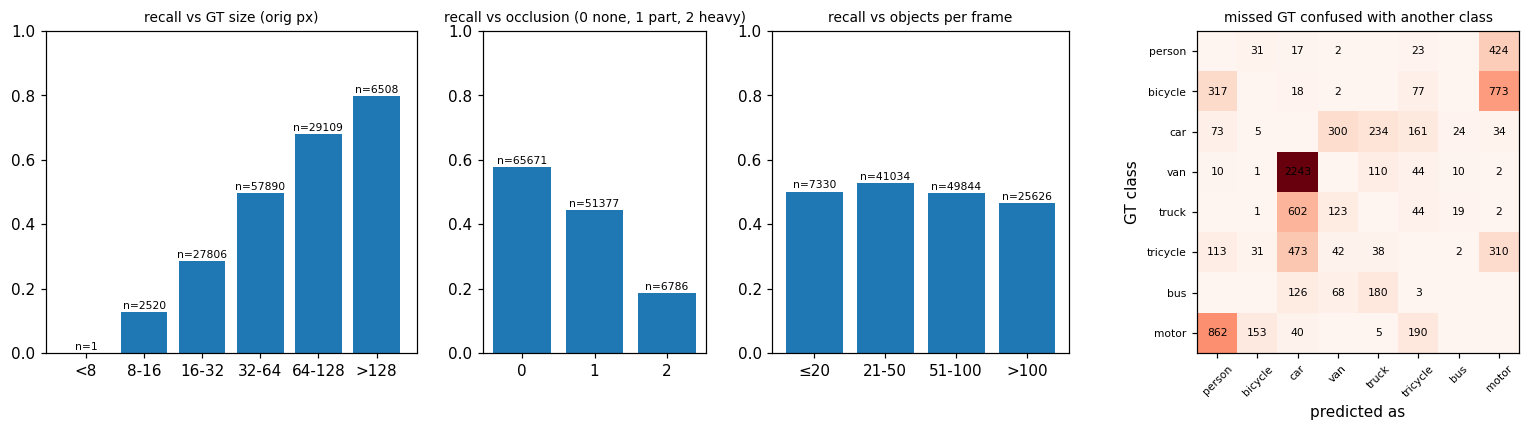

In [18]:
if DO_ANALYSIS:
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), gridspec_kw={"width_ratios": [1, 0.6, 0.8, 1.2]})
    for a, col, title in zip(ax[:3], ["size_bin", "occlusion", "density"],
                             ["GT size (orig px)", "occlusion (0 none, 1 part, 2 heavy)", "objects per frame"]):
        r = gt.groupby(col, observed=True)["matched"].agg(["mean", "size"])
        a.bar(r.index.astype(str), r["mean"])
        for i, (v, s) in enumerate(zip(r["mean"], r["size"])):
            a.text(i, v + 0.01, f"n={s}", ha="center", fontsize=7)
        a.set_title(f"recall vs {title}", fontsize=9)
        a.set_ylim(0, 1)
    conf = gt[gt["confused_with"] >= 0]
    cm = pd.crosstab(conf["cls"], conf["confused_with"]).reindex(index=range(8), columns=range(8), fill_value=0)
    ax[3].imshow(cm.values, cmap="Reds")
    for (i, j), v in np.ndenumerate(cm.values):
        if v:
            ax[3].text(j, i, v, ha="center", va="center", fontsize=7)
    ax[3].set_xticks(range(8), common.CLASSES, rotation=45, fontsize=7)
    ax[3].set_yticks(range(8), common.CLASSES, fontsize=7)
    ax[3].set_xlabel("predicted as")
    ax[3].set_ylabel("GT class")
    ax[3].set_title("missed GT confused with another class", fontsize=9)
    fig.savefig(IMG_DIR / "02_frcnn_error_breakdown.png")
    plt.show()

### 7.4 Failure cases
Frames picked automatically. Green: correct; red: missed GT; magenta: wrong class; orange: poor box; blue: duplicate; yellow: background FP; gray: ignored region.

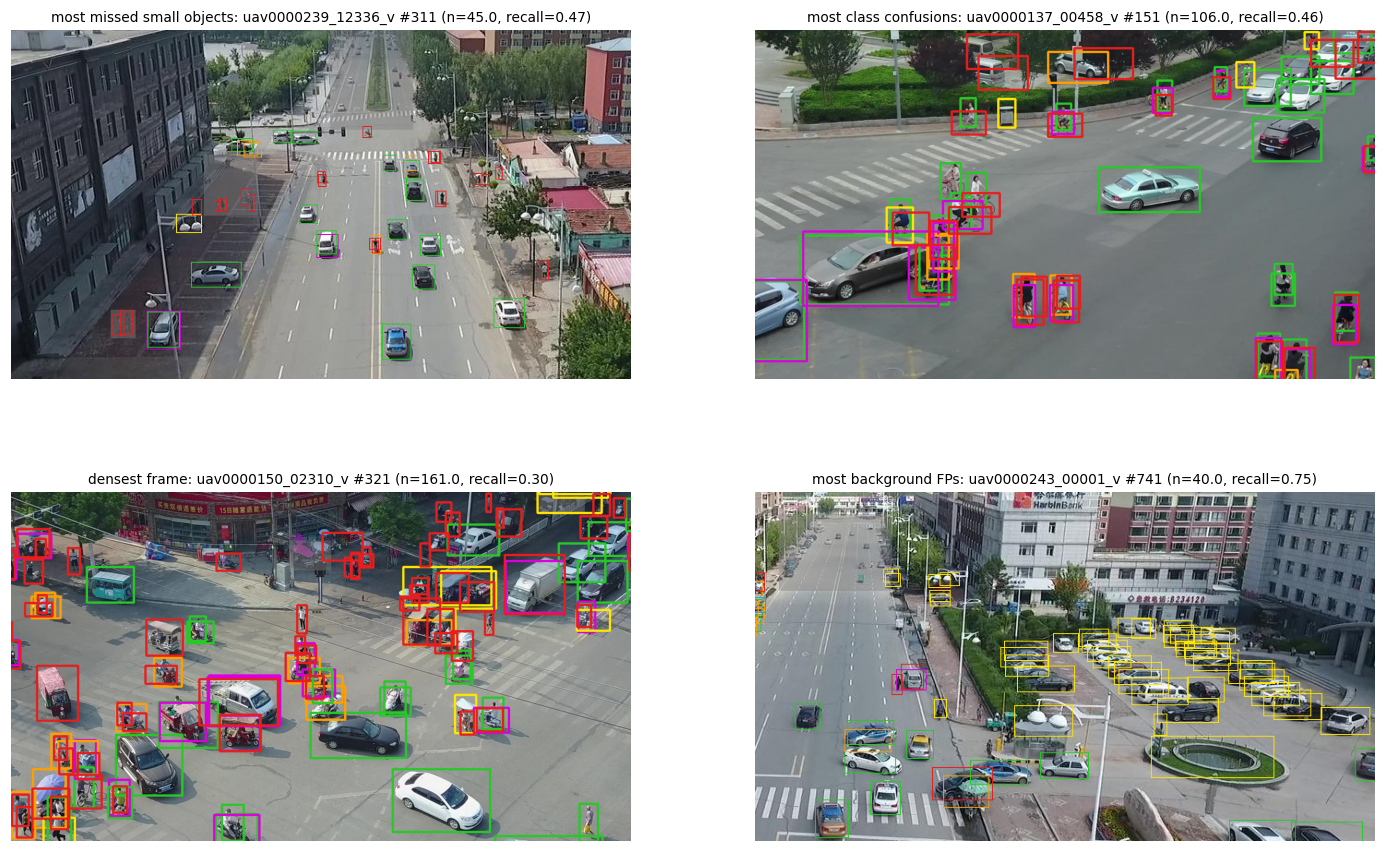

In [19]:
if DO_ANALYSIS:
    per = gt.assign(small_miss=(~gt["matched"]) & (gt["side"] < 16), conf=gt["confused_with"] >= 0)
    per = per.groupby("img_id").agg(small_miss=("small_miss", "sum"), conf=("conf", "sum"),
                                    n=("cls", "size"), recall=("matched", "mean"))
    per["bkg"] = dt[dt["type"] == "bkg"].groupby("img_id").size().reindex(per.index, fill_value=0)
    cases = {"most missed small objects": per["small_miss"].idxmax(),
             "most class confusions": per["conf"].idxmax(),
             "densest frame": per["n"].idxmax(),
             "most background FPs": per["bkg"].idxmax()}
    fig, ax = plt.subplots(2, 2, figsize=(16, 10))
    for a, (title, iid) in zip(ax.ravel(), cases.items()):
        a.imshow(tvt.draw_errors(iid, images, anns, gt, dt, crop="auto"))
        r = per.loc[iid]
        a.set_title(f"{title}: {images.loc[iid, 'clip']} #{images.loc[iid, 'frame_id']} "
                    f"(n={r['n']}, recall={r['recall']:.2f})", fontsize=9)
        a.axis("off")
    fig.savefig(IMG_DIR / "02_frcnn_failure_cases.png")
    plt.show()

1. **Tiny distant objects** (top-left): people and motorbikes far from the camera are 5–15 px and are missed; at this size the backbone features (stride ≥ 4) hold almost no detail.
2. **Riders** (top-right): a person on a motorbike or bicycle is annotated as two objects that overlap almost fully; the model often predicts one class for both, causing the motor ↔ person ↔ bicycle confusions.
3. **Dense crowded scene** (bottom-left, 161 objects, recall 0.30): small, overlapping tricycles and motorbikes; NMS at IoU 0.5 can remove true neighbours, and the RoIs of adjacent objects share features.
4. **Background false positives** (bottom-right): most yellow boxes are parked cars in a car park that are not annotated and not marked as ignored, so many of these "errors" are missing labels rather than model errors.

## 8. Outputs
Merge this session's `results.csv` with the repo copy into `results_merged.csv`, list saved images.

In [20]:
if MODE == "full" and RESULTS.exists():
    merged = WORK / "results_merged.csv"
    try:
        urllib.request.urlretrieve(REPO_RAW + "results.csv", merged)
    except Exception as e:
        print("repo results.csv not available:", e)
        merged.unlink(missing_ok=True)
    common.merge_results(str(RESULTS), str(merged))
    print(f"{merged}: {len(pd.read_csv(merged))} rows")
print("images:", sorted(p.name for p in IMG_DIR.glob("02_*.png")))

/kaggle/working/results_merged.csv: 60 rows
images: ['02_frcnn_comparison.png', '02_frcnn_error_breakdown.png', '02_frcnn_failure_cases.png', '02_frcnn_loss_curves.png', '02_frcnn_proposal_sweep.png', '02_frcnn_rpn_vs_head.png']


## 9. Conclusions
- **Best two-stage model: `frcnn_anch05`** — OOF mAP 0.116, AP50 0.264, AP_small 0.034, 23 FPS on a T4. Smaller anchors help small objects but cost a little on large ones (bus AP 0.18 → 0.15).
- **Default 1000 test-time proposals are optimal**; 300 is a good speed/accuracy trade-off (−0.004 mAP, +37% FPS).
- **Recall is limited by the second stage, not the RPN:** proposals cover 77% of 8–16 px objects, but only 51% end up as correct detections. Small objects need more pixels: higher input resolution or tiled inference (SAHI) is the next step for the final pipeline.
- **Similar classes** (van/car, motor/bicycle/person) and **missing annotations** (unlabelled parked cars counted as false positives) are the other main error sources.